In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from IPython.display import display


import project_images_loader as pil
from tqdm import tqdm

import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc

import SimpleITK as sitk
import test_code.dfield_approach_elastix.constants as cts
import metrics_computer as metrics_computer


np.set_printoptions(precision=4)


Important regions of the brain

lateral ventricles (R:43, L:4)
hipocampus (R:53, L:17)
talamus (R:49, L:10)
cortex (R:42, L:3)
    entorhinal cortex (R:2006, L:1006)
    inferior temporal gyri (R:2009, L:1009)
    superior parietal (R:2029, L:1029)
    middle frontal gyrus (R:2027, L:1027)
    superior frontal gyrus (R:2028, L:1028)
    precuneus (R:2025, L:1025)
    cuneus (R:2005, L:1005)

Other founds:
3rd ventricle (14)


# Compute tissue metrics

In [2]:
def compute_tissue_seg_metrics(seg_base, seg_fup):
    seg_indexs = np.unique(np.concatenate([seg_base, seg_fup]).astype(np.uint))
    tissue_metrics = {}
    for tissue_id in np.unique(seg_indexs):
        mask_base = seg_base == tissue_id
        mask_fup = seg_fup == tissue_id

        dice = util.compute_dice_coefficient(mask_base, mask_fup)
        vol_diff = np.sum(mask_fup) - np.sum(mask_base)
        vol_diff_perc = vol_diff / np.sum(mask_base)
        tissue_metrics[tissue_id] = (dice, vol_diff_perc)

    return tissue_metrics


id = "00039"
simple=True

seg_base, _ = nfc.load_image_sitk(pil.get_segmentation_path_name(3, id, simple=simple, absolute=True))
seg_fup, _ = nfc.load_image_sitk(pil.get_segmentation_path_name(4, id, simple=simple, absolute=True))

tissue_seg_metrics = compute_tissue_seg_metrics(seg_base, seg_fup)
tissue_mag_df = pd.DataFrame.from_dict(tissue_seg_metrics, orient='index', columns=['dice', 'vol_diff'])

with pd.option_context('display.max_rows', None):
    display(tissue_mag_df)

,dice,vol_diff
0,0.992374,-0.002406
2,0.901296,-0.016824
3,0.792759,0.027744
4,0.868695,0.277337
5,0.787739,0.029549
7,0.862005,-0.032780
8,0.885370,0.033082
10,0.908377,0.021164
11,0.893162,-0.024761
12,0.896661,0.027174


# Compute dfield tissue metrics

,jac_min,jac_max,jac_mean,jac_std,div_min,div_max,div_mean,div_std,mag_min,mag_max,mag_mean,mag_std
0,0.315168,2.228833,0.999539,0.038864,-0.819271,0.794020,-0.001302,0.034008,0.000000,4.664699,0.124281,0.350094
42,0.456472,1.646102,1.006479,0.086921,-0.530489,0.581126,0.001494,0.081302,0.019220,3.575346,0.887641,0.369987
41,0.530837,1.404917,1.005209,0.079636,-0.545179,0.518103,-0.001700,0.071631,0.015789,3.475621,0.844431,0.304272
60,0.706017,1.553223,1.054943,0.106477,-0.133869,0.496867,0.050615,0.093441,0.069340,1.331168,0.672471,0.202979
2,0.537474,1.492579,0.998635,0.075820,-0.534864,0.482085,0.019087,0.068385,0.019589,2.760612,0.861000,0.313206
3,0.508778,1.681658,1.000809,0.087256,-0.661294,0.481810,0.010462,0.078858,0.024680,3.122561,0.897093,0.367821
16,0.810960,1.307551,1.028104,0.058017,-0.274139,0.401617,-0.009459,0.088074,0.030132,1.727594,0.776764,0.342486
43,0.564956,1.339923,1.011847,0.120169,-0.243460,0.304862,0.067245,0.093539,0.084699,2.141245,0.967949,0.319462
47,0.481914,1.214763,0.992624,0.071699,-0.193037,0.295137,0.007301,0.059955,0.441044,3.016459,1.224518,0.325071
17,0.738729,1.240961,0.979690,0.084503,-0.366927,0.274347,0.017278,0.097142,0.118513,2.061202,0.923093,0.306555


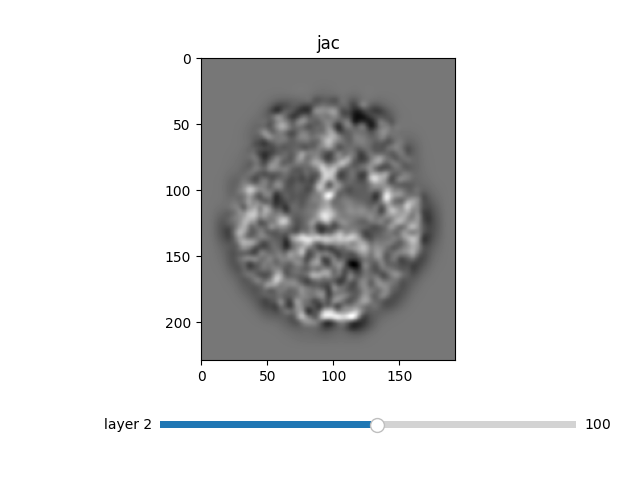

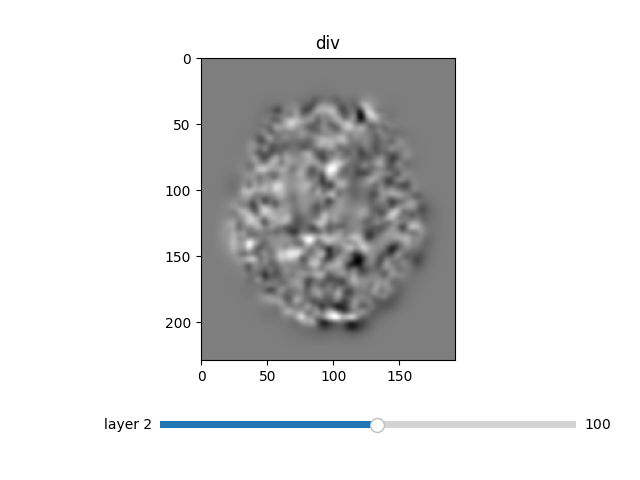

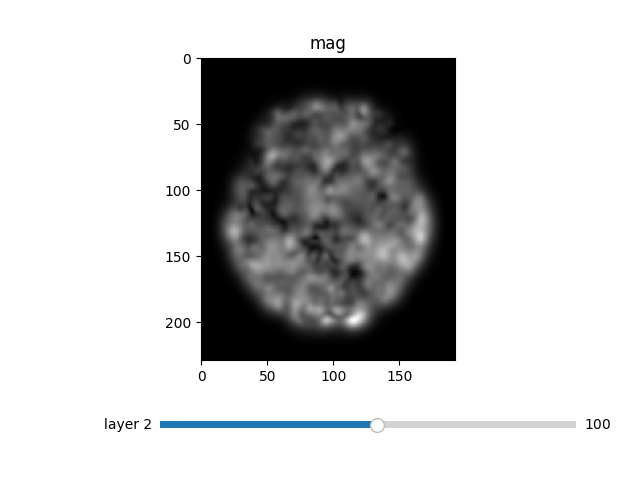

In [31]:
%matplotlib widget

JACOBIAN = 'jac'
DIVERGENCE = 'div'
MAGNITUDE = 'mag'

def get_colums_names(att):
    return [f'{att}_min', f'{att}_max', f'{att}_mean', f'{att}_std']


def compute_dfield_tissue_metrics(dfield_att, seg):
    tissue_metrics = {}
    for tissue_id in np.unique(seg):
        mask_i = seg == tissue_id
        jac_dfield_i = dfield_att[mask_i]
        tissue_metrics[tissue_id] = util.get_basic_metrics(jac_dfield_i)

    return tissue_metrics


def compute_tisue_metrics_by_dfield_att(att=JACOBIAN, id="00039", simple=False):
    seg, _ = nfc.load_image_sitk(pil.get_segmentation_path_name(3, id, simple=True, absolute=True))
    dfield, dfield_sitk = nfc.load_image_sitk(cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_DFIELD))
    
    if att == JACOBIAN:
        dfield_att = metrics_computer.compute_dfield_jacobian(dfield_sitk)
    elif att == DIVERGENCE:
        dfield_att = metrics_computer.compute_dfield_divergence(dfield)
    elif att == MAGNITUDE:
        dfield_att = metrics_computer.compute_dfield_magnitude(dfield)

    tissue_metrics_dict = compute_dfield_tissue_metrics(dfield_att, seg)
    return tissue_metrics_dict, dfield_att, seg


tissue_jac_dict, dfield_jac, seg = compute_tisue_metrics_by_dfield_att(att=JACOBIAN, id="00039", simple=True)
tissue_div_dict, dfield_div, _ = compute_tisue_metrics_by_dfield_att(att=DIVERGENCE, id="00039", simple=True)
tissue_mag_dict, dfield_mag, _ = compute_tisue_metrics_by_dfield_att(att=MAGNITUDE, id="00039", simple=True)


tissue_jac_df = pd.DataFrame.from_dict(tissue_jac_dict, orient='index', columns=get_colums_names(JACOBIAN))
tissue_div_df = pd.DataFrame.from_dict(tissue_div_dict, orient='index', columns=get_colums_names(DIVERGENCE))
tissue_mag_df = pd.DataFrame.from_dict(tissue_mag_dict, orient='index', columns=get_colums_names(MAGNITUDE))

tissue_metrics_df = pd.concat([tissue_jac_df, tissue_div_df, tissue_mag_df], axis=1)
tissue_metrics_df.to_csv(f'{current_path}/tissue_metrics.csv')
tissue_metrics_df_sorted = tissue_metrics_df.sort_values(by='div_max', ascending=False)
with pd.option_context('display.max_rows', None):
    display(tissue_metrics_df_sorted)

fc.imgshow_3D("jac", np.transpose(dfield_jac, (2, 1, 0)))
fc.imgshow_3D("div", np.transpose(dfield_div, (2, 1, 0)))
fc.imgshow_3D("mag", np.transpose(dfield_mag, (2, 1, 0)))

# Evaluate all dfield divergences

In [ ]:
def evaluate_all_dfield_divergences():
    matching_ids = pil.get_matching_ids()

    for id in matching_ids:
        dfield_path_name = cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_DFIELD)
        jac_dfield = metrics_computer.compute_dfield_divergence(nfc.load_image_sitk(dfield_path_name)[0])
        # min_jac = np.min(jac_dfield)
        # if min_jac < 0:
        print(f"{id}: {util.get_basic_metrics_str(jac_dfield)}")

evaluate_all_dfield_divergences()

00039: min: -0.8193, max: 0.7940, mean: -0.0000, std: 0.0420
00046: min: -1.0109, max: 0.7226, mean: 0.0000, std: 0.0517
00053: min: -0.7355, max: 0.8207, mean: -0.0000, std: 0.0465
00077: min: -0.7517, max: 0.8469, mean: 0.0000, std: 0.0434
00091: min: -0.9062, max: 0.9013, mean: -0.0000, std: 0.0471
00107: min: -0.8175, max: 0.8627, mean: 0.0000, std: 0.0542
00121: min: -0.8069, max: 0.7407, mean: -0.0000, std: 0.0396
00138: min: -0.7119, max: 0.7407, mean: -0.0000, std: 0.0475
00145: min: -0.6764, max: 1.1419, mean: 0.0000, std: 0.0495
00169: min: -0.7719, max: 0.7232, mean: 0.0000, std: 0.0416
00183: min: -0.8192, max: 0.7611, mean: -0.0000, std: 0.0430
00220: min: -0.9173, max: 1.2406, mean: -0.0000, std: 0.0485
00237: min: -0.7494, max: 0.6410, mean: -0.0000, std: 0.0454
00244: min: -0.8159, max: 0.6465, mean: -0.0000, std: 0.0511
00251: min: -1.0823, max: 0.7832, mean: -0.0000, std: 0.0459
00268: min: -1.0549, max: 0.7687, mean: 0.0000, std: 0.0507
00299: min: -1.1489, max: 1.01

# Evaluate all dfield jacobians

In [4]:
def evaluate_all_dfield_jacobians():
    matching_ids = pil.get_matching_ids()

    for id in matching_ids:
        dfield_path_name = cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_DFIELD)
        jac_dfield = metrics_computer.compute_dfield_jacobian(nfc.load_image_sitk(dfield_path_name)[1])
        min_jac = np.min(jac_dfield)
        if min_jac < 0:
            print(f"{id}: {util.get_basic_metrics_str(jac_dfield)}")

    # print(f"{id}: {get_basic_metrics_str(jac_dfield)}")
# evaluate_all_dfield_jacobians()



# (not same patient) 01388: min: -1.0736, max: 4.6183, mean: 1.0000, std: 0.2147
# (same patient) 02408: min: -2.0260, max: 4.4923, mean: 1.0000, std: 0.1877
# (same patient) # 03139: min: -1.4722, max: 4.0456, mean: 1.0000, std: 0.0812
# (not same patient) 06611: min: -1.5924, max: 4.9465, mean: 1.0000, std: 0.1907
# (same patient) 02507: min: -0.7068, max: 3.6092, mean: 1.0000, std: 0.0665
# (same patient OK to use) # 11608: min: -0.9586, max: 4.1549, mean: 1.0000, std: 0.0889


# 00251: min: -0.0339, max: 2.0161, mean: 1.0000, std: 0.0481
# 00268: min: -0.0222, max: 2.3118, mean: 1.0000, std: 0.0553
# 00275: min: -0.0384, max: 2.5144, mean: 1.0000, std: 0.0520
# 00374: min: -0.1305, max: 2.1304, mean: 1.0000, std: 0.0556
# 00381: min: -0.1377, max: 2.5407, mean: 1.0000, std: 0.0990
# 00411: min: -0.0114, max: 3.0003, mean: 1.0000, std: 0.0587
# 00527: min: -0.1041, max: 1.9465, mean: 1.0000, std: 0.0473
# 00626: min: -0.0998, max: 2.6628, mean: 1.0000, std: 0.0535
# 00862: min: -0.2126, max: 2.9343, mean: 1.0000, std: 0.0810
# 01005: min: -0.1366, max: 2.8722, mean: 1.0000, std: 0.0693
# 01067: min: -0.0040, max: 2.6702, mean: 1.0000, std: 0.0563
# 01388: min: -1.0736, max: 4.6183, mean: 1.0000, std: 0.2147
# 01661: min: -0.0047, max: 2.2129, mean: 1.0000, std: 0.0569
# 01807: min: -0.0950, max: 2.3663, mean: 1.0000, std: 0.0582
# 02187: min: -0.0893, max: 1.9249, mean: 1.0000, std: 0.0550
# 02309: min: -0.3660, max: 3.7315, mean: 1.0000, std: 0.0739
# 02347: min: -0.1994, max: 2.9636, mean: 1.0000, std: 0.0613
# 02408: min: -2.0260, max: 4.4923, mean: 1.0000, std: 0.1877
# 02507: min: -0.7068, max: 3.6092, mean: 1.0000, std: 0.0665
# 02941: min: -0.0568, max: 1.9762, mean: 1.0000, std: 0.0617
# 03139: min: -1.4722, max: 4.0456, mean: 1.0000, std: 0.0812
# 03306: min: -0.1115, max: 2.3249, mean: 1.0000, std: 0.0536
# 03375: min: -0.1814, max: 3.3439, mean: 1.0000, std: 0.0947
# 03405: min: -0.0177, max: 1.8074, mean: 1.0000, std: 0.0553
# 03498: min: -0.3974, max: 2.9140, mean: 1.0000, std: 0.0710
# 04600: min: -0.0247, max: 2.6262, mean: 1.0000, std: 0.0563
# 04730: min: -0.0708, max: 2.1916, mean: 1.0000, std: 0.0617
# 05287: min: -0.0123, max: 2.2531, mean: 1.0000, std: 0.0550
# 05478: min: -0.1774, max: 2.5919, mean: 1.0000, std: 0.0659
# 06123: min: -0.1059, max: 2.2267, mean: 1.0000, std: 0.0610
# 06567: min: -0.0484, max: 2.3864, mean: 1.0000, std: 0.0543
# 06611: min: -1.5924, max: 4.9465, mean: 1.0000, std: 0.1907
# 07144: min: -0.0043, max: 2.5583, mean: 1.0000, std: 0.0704
# 07465: min: -0.0583, max: 2.0573, mean: 1.0000, std: 0.0613
# 08608: min: -0.2347, max: 2.7409, mean: 1.0000, std: 0.0599
# 08660: min: -0.2965, max: 2.6783, mean: 1.0000, std: 0.0564
# 09346: min: -0.0316, max: 2.1952, mean: 1.0000, std: 0.0553
# 09377: min: -0.0757, max: 3.1893, mean: 1.0000, std: 0.0589
# 09537: min: -0.1029, max: 1.8103, mean: 1.0000, std: 0.0450
# 09902: min: -0.3757, max: 2.8952, mean: 1.0000, std: 0.0628
# 10007: min: -0.0755, max: 2.4229, mean: 1.0000, std: 0.0563
# 11042: min: -0.0091, max: 2.6802, mean: 1.0000, std: 0.0535
# 11097: min: -0.0369, max: 2.5051, mean: 1.0000, std: 0.0532
# 11325: min: -0.2732, max: 2.3622, mean: 1.0000, std: 0.0590
# 11608: min: -0.9586, max: 4.1549, mean: 1.0000, std: 0.0889
# 11615: min: -0.0249, max: 2.3697, mean: 1.0000, std: 0.0554
# 12131: min: -0.0192, max: 2.9235, mean: 1.0000, std: 0.0577
# 12315: min: -0.2285, max: 2.8798, mean: 1.0000, std: 0.0599
# 12674: min: -0.0155, max: 2.3962, mean: 1.0000, std: 0.0489
# 12759: min: -0.1183, max: 1.7686, mean: 1.0000, std: 0.0606
# 13138: min: -0.2820, max: 1.9050, mean: 1.0000, std: 0.0544
# 13534: min: -0.0075, max: 2.3413, mean: 1.0000, std: 0.0522
# 13558: min: -0.0578, max: 1.9917, mean: 1.0000, std: 0.0488
# 14029: min: -0.0163, max: 1.9425, mean: 1.0000, std: 0.0605
# 14494: min: -0.1020, max: 2.1950, mean: 1.0000, std: 0.0569
# 14654: min: -0.0399, max: 4.1050, mean: 1.0000, std: 0.0631
# 16801: min: -0.0396, max: 2.0690, mean: 1.0000, std: 0.0484

00251: min: -0.0339, max: 2.0161, mean: 1.0000, std: 0.0481
00268: min: -0.0222, max: 2.3118, mean: 1.0000, std: 0.0553
00275: min: -0.0384, max: 2.5144, mean: 1.0000, std: 0.0520
00374: min: -0.1305, max: 2.1304, mean: 1.0000, std: 0.0556
00381: min: -0.1377, max: 2.5407, mean: 1.0000, std: 0.0990
00411: min: -0.0114, max: 3.0003, mean: 1.0000, std: 0.0587
00527: min: -0.1041, max: 1.9465, mean: 1.0000, std: 0.0473
00626: min: -0.0998, max: 2.6628, mean: 1.0000, std: 0.0535
00862: min: -0.2126, max: 2.9343, mean: 1.0000, std: 0.0810
01005: min: -0.1366, max: 2.8722, mean: 1.0000, std: 0.0693
01067: min: -0.0040, max: 2.6702, mean: 1.0000, std: 0.0563
01388: min: -1.0736, max: 4.6183, mean: 1.0000, std: 0.2147
01661: min: -0.0047, max: 2.2129, mean: 1.0000, std: 0.0569
01807: min: -0.0950, max: 2.3663, mean: 1.0000, std: 0.0582
02187: min: -0.0893, max: 1.9249, mean: 1.0000, std: 0.0550
02309: min: -0.3660, max: 3.7315, mean: 1.0000, std: 0.0739
02347: min: -0.1994, max: 2.9636, mean: 

# Compare loading images with nibabel or simple itk

(193, 229, 193)
(193, 229, 193)
0.02912971706856826
min: 0.3151679899465013, max: 2.2288325972240504, mean: 1.0000002539306203, std: 0.04733078822961778
min: 0.31516796350479126, max: 2.228832721710205, mean: 1.000000238418579, std: 0.04733077436685562


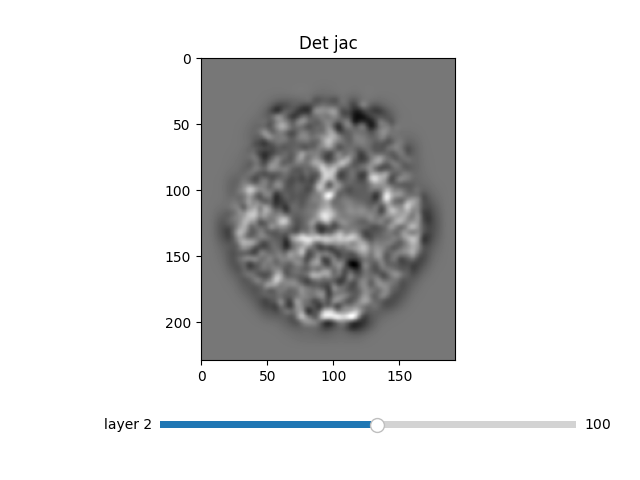

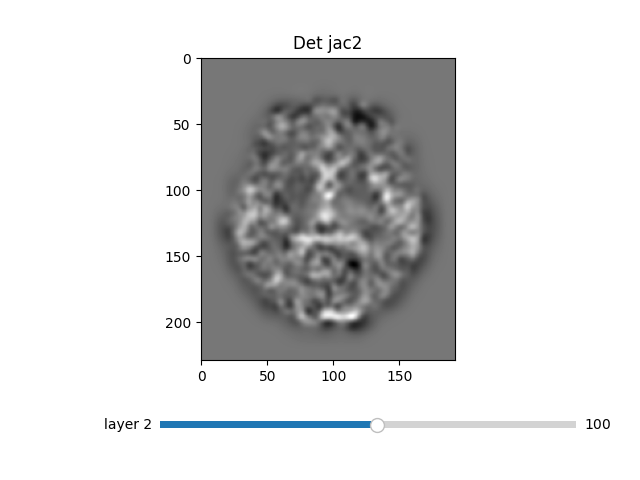

In [ ]:
%matplotlib widget


def compare_loading_images_nibabel_vs_sitk(id="00039"):
    dfield_path_name = cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_DFIELD)

    img_dfield, _ = nfc.load_nifti(dfield_path_name)
    img_dfield = img_dfield[:,:,:,0,:]
    img_dfield = np.transpose(img_dfield, (2,1,0,3))

    jac_dfield = metrics_computer.compute_dfield_jacobian(sitk.GetImageFromArray(img_dfield, isVector=True))

    jac_dfield2 = metrics_computer.compute_dfield_jacobian(nfc.load_image_sitk(dfield_path_name)[1])
    # jac_dfield2 = np.transpose(jac_dfield2, (2,1,0))

    print(jac_dfield.shape )
    print(jac_dfield2.shape )
    print(np.sum(jac_dfield - jac_dfield2))

    print(f"min: {np.min(jac_dfield)}, max: {np.max(jac_dfield)}, mean: {np.mean(jac_dfield)}, std: {np.std(jac_dfield)}")
    print(f"min: {np.min(jac_dfield2)}, max: {np.max(jac_dfield2)}, mean: {np.mean(jac_dfield2)}, std: {np.std(jac_dfield2)}")

    fc.imgshow_3D("Det jac", np.transpose(jac_dfield, (2,1,0)))
    fc.imgshow_3D("Det jac2", np.transpose(jac_dfield2, (2,1,0)))


compare_loading_images_nibabel_vs_sitk("00039")